Loaded LS_sim_no_noise_linear_friction: 3899 steps
Loaded HNN_sim_no_noise_linear_friction: 500 steps


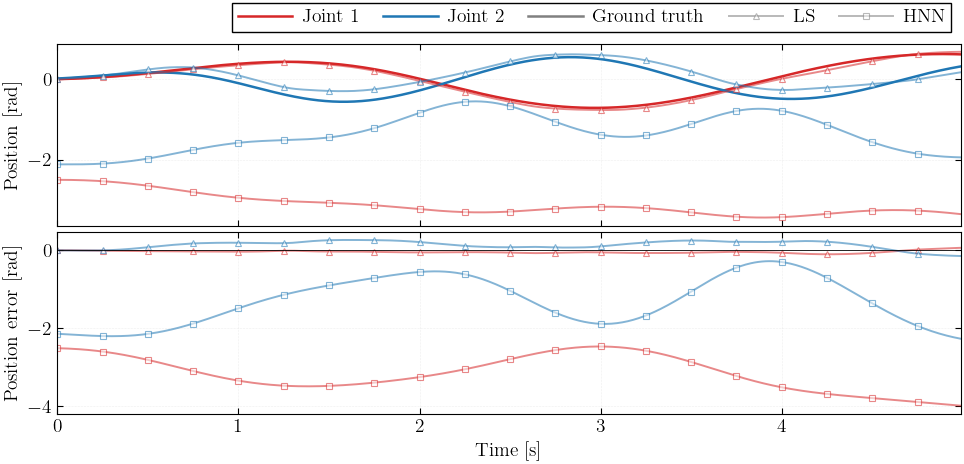

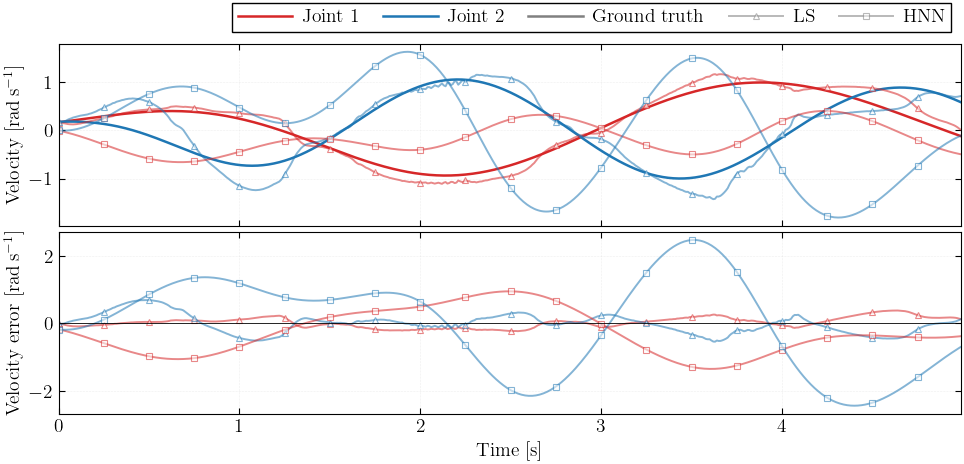

In [6]:
## PLOTTING FOR HNN AND LS

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# IEEE STYLE
# ============================================================
mpl.rcdefaults()
mpl.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.top": True,
    "ytick.right": True,
    "axes.grid": True,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.linestyle": ":",
    "lines.linewidth": 1.4,
    "legend.frameon": True,
    "legend.framealpha": 1.0,
    "legend.edgecolor": "black",
    "legend.fancybox": False,
    "legend.handlelength": 2.8,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
})

# ============================================================
# LOAD MODELS
# ============================================================
model_files = [
    "results_LS_sim_no_noise_linear_friction.npz",
    "results_HNN_sim_no_noise_linear_friction.npz",
    # "results_baseline.npz",   # add more as needed
]



models = {}
for f in model_files:
    d = np.load(f, allow_pickle=True)
    name = str(d["model_name"])
    models[name] = d
    print(f"Loaded {name}: {len(d['true_theta1'])} steps")

ref = list(models.values())[0]
dt = float(ref["dt"])
T = min(len(ref["true_theta1"]),
        *[len(m["pred_theta1"]) for m in models.values()])
time = np.arange(T) * dt

# ============================================================
# VISUAL ENCODING
#   Colour = joint  (red = joint 1, blue = joint 2)
#   Truth  = full opacity, solid, no marker
#   HNN    = reduced alpha, square markers
#   LS     = reduced alpha, triangle markers
# ============================================================
C_J1 = "#D62728"   # red
C_J2 = "#1F77B4"   # blue

GT_LW = 1.8
MD_LW = 1.4
ALPHA_MODEL = 0.55

N_MARKER = max(1, T // 20)

MODEL_CFG = {
    # name: (marker, alpha, display_label)
    "LS_sim_no_noise_linear_friction":  ("^", ALPHA_MODEL, "LS"),
    "HNN_sim_no_noise_linear_friction": ("s", ALPHA_MODEL, "HNN"),
}

# Fallback
_FALLBACK_MK = ["^", "s", "D", "v", "o"]
for i, name in enumerate(models):
    if name not in MODEL_CFG:
        MODEL_CFG[name] = (_FALLBACK_MK[i % len(_FALLBACK_MK)],
                           ALPHA_MODEL, name.replace("_", r"\_"))

FIG_W = 10


def _plot_line(ax, t, y, color, lw, alpha=1.0, marker=None):
    """Helper to plot with optional sparse markers."""
    kw = dict(color=color, lw=lw, alpha=alpha)
    if marker:
        kw.update(marker=marker, markevery=N_MARKER, markersize=4.5,
                  markerfacecolor="white", markeredgewidth=0.8,
                  markeredgecolor=color)
    ax.plot(t, y, **kw)


# ============================================================
# FIGURE 1 — POSITION + POSITION ERROR
# ============================================================
fig1, (ax_pos, ax_epos) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Position: ground truth (solid, full opacity) ----
_plot_line(ax_pos, time, ref["true_theta1"][:T], C_J1, GT_LW)
_plot_line(ax_pos, time, ref["true_theta2"][:T], C_J2, GT_LW)

# ---- Position: model predictions ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    _plot_line(ax_pos, time, data["pred_theta1"][:T], C_J1, MD_LW, alph, mk)
    _plot_line(ax_pos, time, data["pred_theta2"][:T], C_J2, MD_LW, alph, mk)

ax_pos.set_ylabel(r"Position [rad]")

# ---- Position error (no ground truth) ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    err_t1 = data["pred_theta1"][:T] - ref["true_theta1"][:T]
    err_t2 = data["pred_theta2"][:T] - ref["true_theta2"][:T]
    _plot_line(ax_epos, time, err_t1, C_J1, MD_LW, alph, mk)
    _plot_line(ax_epos, time, err_t2, C_J2, MD_LW, alph, mk)

ax_epos.axhline(0, color="black", ls="-", lw=0.6)
ax_epos.set_ylabel(r"Position error [rad]")
ax_epos.set_xlabel(r"Time [s]")

# ---- Shared legend ----
h_joint = [
    Line2D([], [], color=C_J1, ls="-", lw=GT_LW, label=r"Joint 1"),
    Line2D([], [], color=C_J2, ls="-", lw=GT_LW, label=r"Joint 2"),
]
h_source = [
    Line2D([], [], color="gray", ls="-", lw=GT_LW,
           marker="None", label="Ground truth"),
]
for name in models:
    mk, alph, lbl = MODEL_CFG[name]
    h_source.append(
        Line2D([], [], color="gray", ls="-", lw=MD_LW, alpha=alph,
               marker=mk, markersize=4.5,
               markerfacecolor="white", markeredgewidth=0.8,
               markeredgecolor="gray", label=lbl)
    )

# ---- Figure 1 ----
ax_pos.set_xlim(time[0], time[-1])

leg1 = ax_pos.legend(
    handles=h_joint + h_source,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_joint) + len(h_source),
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig1.savefig("position_comparison.png", format="png", dpi=600)
plt.show()


# ============================================================
# FIGURE 2 — VELOCITY + VELOCITY ERROR
# ============================================================
fig2, (ax_vel, ax_evel) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Velocity: ground truth ----
_plot_line(ax_vel, time, ref["true_dtheta1"][:T], C_J1, GT_LW)
_plot_line(ax_vel, time, ref["true_dtheta2"][:T], C_J2, GT_LW)

# ---- Velocity: model predictions ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    _plot_line(ax_vel, time, data["pred_dtheta1"][:T], C_J1, MD_LW, alph, mk)
    _plot_line(ax_vel, time, data["pred_dtheta2"][:T], C_J2, MD_LW, alph, mk)

ax_vel.set_ylabel(r"Velocity [rad\,s$^{-1}$]")

# ---- Velocity error (no ground truth) ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    err_d1 = data["pred_dtheta1"][:T] - ref["true_dtheta1"][:T]
    err_d2 = data["pred_dtheta2"][:T] - ref["true_dtheta2"][:T]
    _plot_line(ax_evel, time, err_d1, C_J1, MD_LW, alph, mk)
    _plot_line(ax_evel, time, err_d2, C_J2, MD_LW, alph, mk)

ax_evel.axhline(0, color="black", ls="-", lw=0.6)
ax_evel.set_ylabel(r"Velocity error [rad\,s$^{-1}$]")
ax_evel.set_xlabel(r"Time [s]")

# ---- Shared legend (reuse handles) ----
h_joint_vel = [
    Line2D([], [], color=C_J1, ls="-", lw=GT_LW, label=r"Joint 1"),
    Line2D([], [], color=C_J2, ls="-", lw=GT_LW, label=r"Joint 2"),
]

ax_vel.set_xlim(time[0], time[-1])

leg2 = ax_vel.legend(
    handles=h_joint_vel + h_source,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_joint_vel) + len(h_source),
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig2.savefig("velocity_comparison.png", format="png", dpi=600)
plt.show()

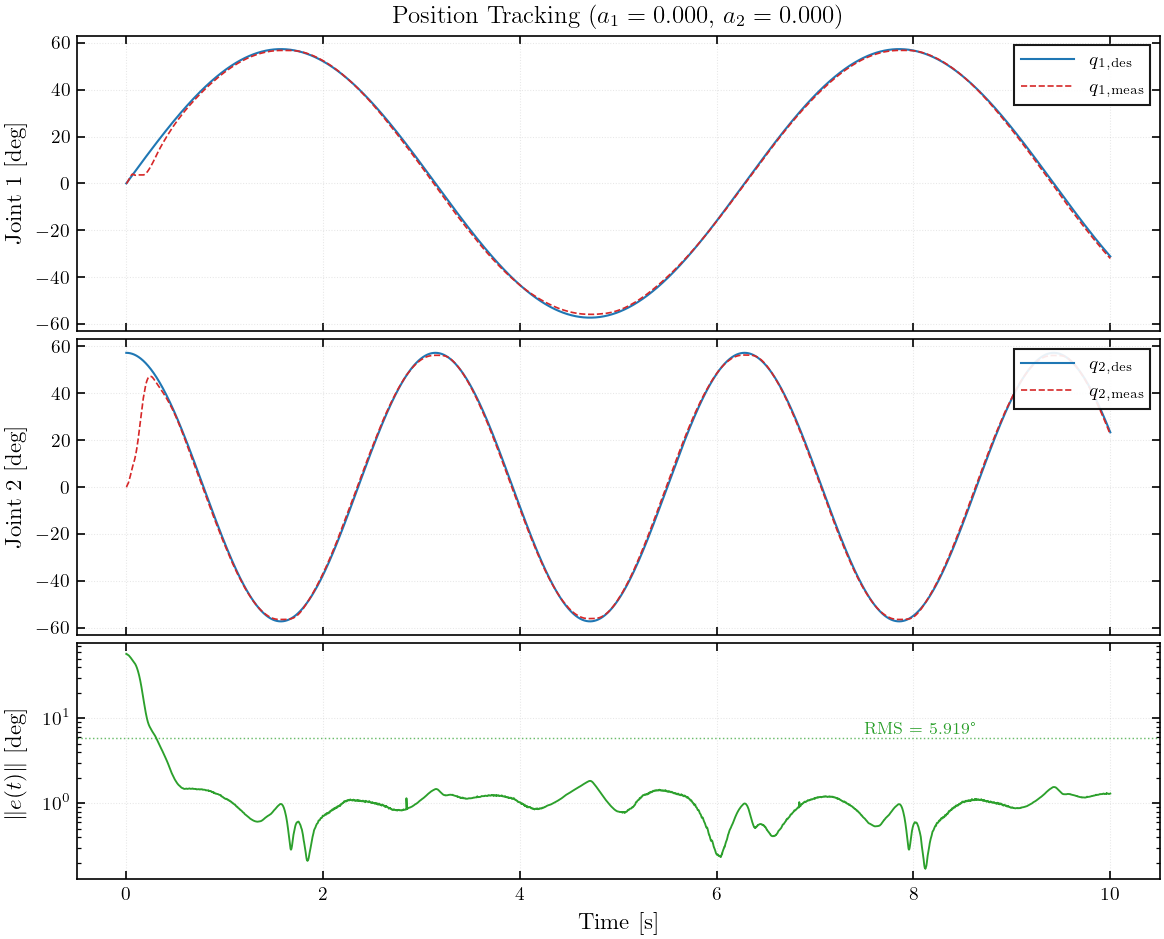

In [10]:
# ── Load & plot tracking performance ─────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.io import loadmat
from pathlib import Path

mpl.rcParams.update({
    'font.family':      'serif',
    'font.size':        10,
    'axes.labelsize':   11,
    'axes.titlesize':   12,
    'legend.fontsize':  9,
    'xtick.labelsize':  9,
    'ytick.labelsize':  9,
    'lines.linewidth':  1.0,
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'grid.linewidth':   0.5,
    'figure.dpi':       150,
    'savefig.dpi':      300,
    'savefig.bbox':     'tight',
})

# ── Load .mat and convert to .npz ────────────────────────────────────
mat_path = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code/KPES_pert_a1_0.000_a2_0.000.mat'   # <-- ADJUST PATH

npz_path = str(Path(mat_path).with_suffix('.npz'))
mat = loadmat(mat_path)

np.savez(npz_path,
         t=mat['t'], dt=mat['dt'],
         phat=mat['phat'], uo=mat['uo'],
         u_ff=mat['u_ff'], u_d=mat['u_d'], u_pert=mat['u_pert'],
         q_desired=mat['q_desired'], q_meas=mat['q_meas'],
         u_total=mat['u_total'], e_track=mat['e_track'],
         a1=mat['a1'], a2=mat['a2'])

d         = np.load(npz_path)
t         = d['t'].flatten()
q_desired = d['q_desired']
q_meas    = d['q_meas']
e_track   = d['e_track']
e_norm    = np.linalg.norm(e_track, axis=1)
a1        = d['a1'].item()
a2        = d['a2'].item()

# ── Plot ─────────────────────────────────────────────────────────────
c_des, c_meas, c_norm = '#1f77b4', '#d62728', '#2ca02c'

fig, axes = plt.subplots(3, 1, figsize=(8, 6.5), sharex=True,
                         gridspec_kw={'height_ratios': [1, 1, 0.8]})

# Joint 1
axes[0].plot(t, np.rad2deg(q_desired[:, 0]), color=c_des,  label=r'$q_{1,\mathrm{des}}$')
axes[0].plot(t, np.rad2deg(q_meas[:, 0]),    color=c_meas, label=r'$q_{1,\mathrm{meas}}$',
             linestyle='--', linewidth=0.8)
axes[0].set_ylabel('Joint 1 [deg]')
axes[0].legend(loc='upper right', framealpha=0.9)
axes[0].set_title(f'Position Tracking  ($a_1={a1:.3f}$, $a_2={a2:.3f}$)')

# Joint 2
axes[1].plot(t, np.rad2deg(q_desired[:, 1]), color=c_des,  label=r'$q_{2,\mathrm{des}}$')
axes[1].plot(t, np.rad2deg(q_meas[:, 1]),    color=c_meas, label=r'$q_{2,\mathrm{meas}}$',
             linestyle='--', linewidth=0.8)
axes[1].set_ylabel('Joint 2 [deg]')
axes[1].legend(loc='upper right', framealpha=0.9)

# Error norm
axes[2].plot(t, np.rad2deg(e_norm), color=c_norm, linewidth=0.9)
axes[2].set_ylabel(r'$\|e(t)\|$ [deg]')
axes[2].set_xlabel('Time [s]')
axes[2].set_yscale('log')

rms = np.rad2deg(np.sqrt(np.mean(e_norm**2)))
axes[2].axhline(rms, color=c_norm, linestyle=':', linewidth=0.7, alpha=0.7)
axes[2].annotate(f'RMS = {rms:.3f}°', xy=(t[-1]*0.75, rms),
                 fontsize=8, color=c_norm, va='bottom')

for a in axes:
    a.tick_params(direction='in')
fig.align_ylabels(axes)
plt.tight_layout(h_pad=0.4)
# fig.savefig(str(Path(mat_path).with_suffix('.pdf')))
plt.show()

Found 5 files
  KPES_pert_a1_0.000_a2_0.000.mat  a1=0.000  a2=0.000
  KPES_pert_a1_0.100_a2_0.200.mat  a1=0.100  a2=0.200
  KPES_pert_a1_0.250_a2_0.500.mat  a1=0.250  a2=0.500
  KPES_pert_a1_0.400_a2_0.800.mat  a1=0.400  a2=0.800
  KPES_pert_a1_0.500_a2_1.000.mat  a1=0.500  a2=1.000


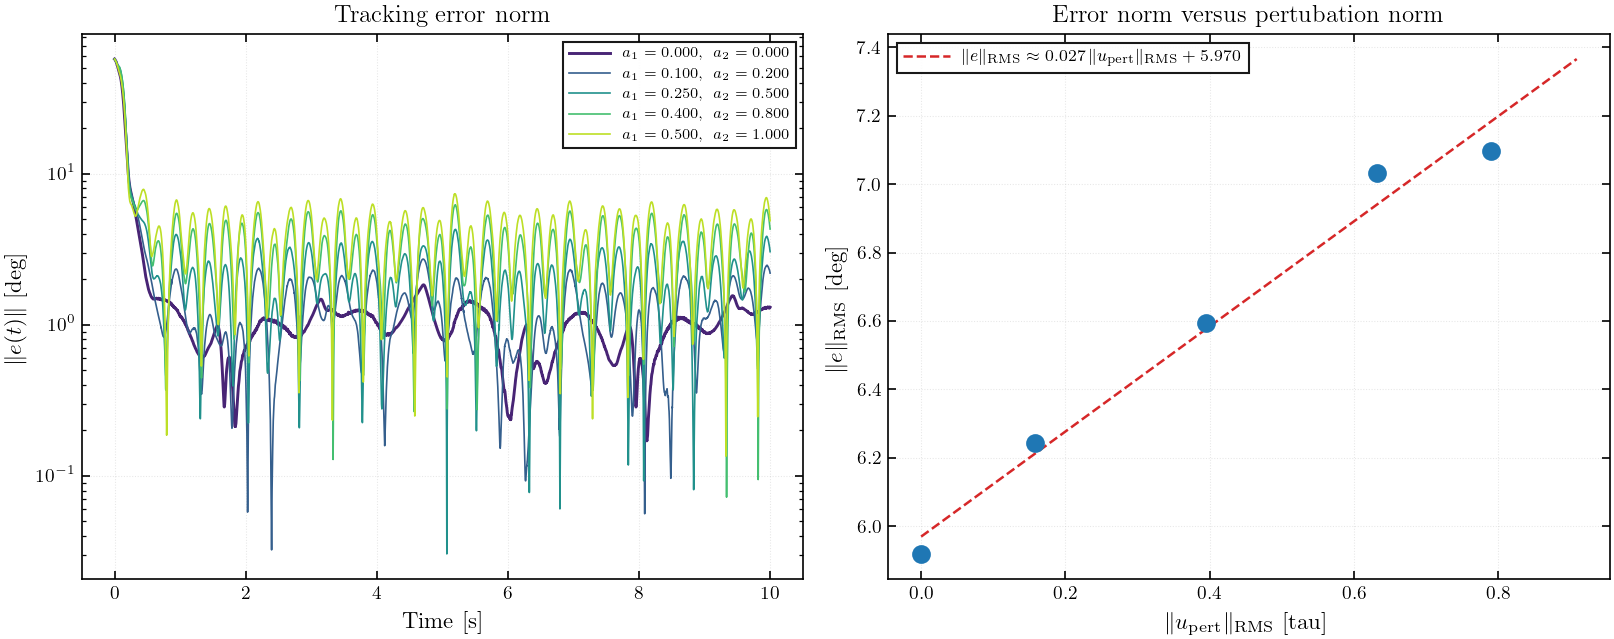

In [12]:
# ── ISS analysis: ||e||_RMS proportional to ||u_pert||_RMS ? ─────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.io import loadmat
from pathlib import Path

mpl.rcParams.update({
    'font.family':      'serif',
    'font.size':        10,
    'axes.labelsize':   11,
    'axes.titlesize':   12,
    'legend.fontsize':  9,
    'xtick.labelsize':  9,
    'ytick.labelsize':  9,
    'lines.linewidth':  1.0,
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'grid.linewidth':   0.5,
    'figure.dpi':       150,
    'savefig.dpi':      300,
    'savefig.bbox':     'tight',
})

# ── Load all experiment files ────────────────────────────────────────
data_dir  = '/Users/lars/Documents/GitHub/Master-Research-Project/Python Code/ISS_exp'
mat_files = sorted(Path(data_dir).glob('KPES_pert_a1_*_a2_*.mat'))
print(f'Found {len(mat_files)} files')

experiments = []
for f in mat_files:
    m  = loadmat(str(f))
    a1 = m['a1'].item()
    a2 = m['a2'].item()
    t  = m['t'].flatten()
    e  = m['e_track']
    u_pert = m['u_pert']

    e_norm_t      = np.linalg.norm(e, axis=1)
    u_pert_norm_t = np.linalg.norm(u_pert, axis=1)

    experiments.append({
        'a1': a1, 'a2': a2, 't': t,
        'e_norm_t':      e_norm_t,
        'u_pert_norm_t': u_pert_norm_t,
        'e_rms':         np.sqrt(np.mean(e_norm_t**2)),
        'u_pert_rms':    np.sqrt(np.mean(u_pert_norm_t**2)),
        'label': f'$a_1={a1:.3f},\\ a_2={a2:.3f}$',
    })
    print(f'  {f.name}  a1={a1:.3f}  a2={a2:.3f}')

experiments.sort(key=lambda x: x['u_pert_rms'])

u_rms = np.array([ex['u_pert_rms'] for ex in experiments])
e_rms = np.array([ex['e_rms'] for ex in experiments])

# ── Figure: 2 panels ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(experiments)))

# ── (a) Error norm time traces (log scale) ───────────────────────────
ax = axes[0]
for i, ex in enumerate(experiments):
    is_nominal = (ex['a1'] == 0 and ex['a2'] == 0)
    ax.plot(ex['t'], np.rad2deg(ex['e_norm_t']), color=cmap[i],
            linewidth=1.4 if is_nominal else 0.8,
            label=ex['label'])
# ax.set_yscale('log')
ax.set_xlabel('Time [s]')
ax.set_ylabel(r'$\|e(t)\|$ [deg]')
ax.set_title('Tracking error norm')
ax.set_yscale('log')
ax.legend(fontsize=7, loc='upper right', framealpha=0.9)

# ── (b) RMS ||e|| vs RMS ||u_pert|| (all points including nominal) ──
ax = axes[1]
ax.plot(u_rms, np.rad2deg(e_rms), 'o', color='#1f77b4',
        markersize=8, zorder=3)

# ISS gain fit including all points: e_rms = gamma * u_pert_rms + beta
A = np.column_stack([u_rms, np.ones(len(u_rms))])
(gamma, beta), *_ = np.linalg.lstsq(A, e_rms, rcond=None)

u_fit = np.linspace(0, u_rms.max() * 1.15, 100)
ax.plot(u_fit, np.rad2deg(gamma * u_fit + beta), '--',
        color='#d62728', linewidth=1.2, zorder=2,
        label=(rf'$\|e\|_{{\mathrm{{RMS}}}} \approx '
               rf'{gamma:.3f}\,\|u_{{\mathrm{{pert}}}}\|_{{\mathrm{{RMS}}}} '
               rf'+ {np.rad2deg(beta):.3f}°$'))

ax.set_xlabel(r'$\|u_{\mathrm{pert}}\|_{\mathrm{RMS}}$ [tau]')
ax.set_ylabel(r'$\|e\|_{\mathrm{RMS}}$ [deg]')
ax.set_title(r'Error norm versus pertubation norm')
ax.legend(fontsize=8, loc='upper left', framealpha=0.9)

for a in axes:
    a.tick_params(direction='in')
plt.tight_layout()
# fig.savefig('ISS_analysis.pdf')
plt.show()

In [ ]:
# ── Controller comparison: trajectory tracking & error norm ──────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.io import loadmat
from pathlib import Path

mpl.rcParams.update({
    'font.family':      'serif',
    'font.size':        10,
    'axes.labelsize':   11,
    'axes.titlesize':   12,
    'legend.fontsize':  9,
    'xtick.labelsize':  9,
    'ytick.labelsize':  9,
    'lines.linewidth':  1.0,
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'grid.linewidth':   0.5,
    'figure.dpi':       150,
    'savefig.dpi':      300,
    'savefig.bbox':     'tight',
})

# ── Load data ────────────────────────────────────────────────────────
# data_dir = "C:\\Users\\S4236610\\Documents\\GitHub\\Master-Research-Project\\Python Code"
data_dir = "/Users/lars/Documents/GitHub/Master-Research-Project/Python Code"

controllers = []

# KPES nominal (a1=0, a2=0)
kpes = loadmat(str(Path(data_dir) / 'KPES_pert_a1_0.000_a2_0.000.mat'))  # <-- ADJUST filename
controllers.append({
    'name':      'KPES (proposed)',
    'color':     '#1f77b4',
    't':         kpes['t'].flatten(),
    'q_desired': kpes['q_desired'],
    'q_meas':    kpes['q_meas'],
    'e_track':   kpes['e_track'],
})

# Other controllers — add as many as needed
for fname, label, color in [
    ('RasconIET_control.mat',  'Rascón (IET)',   '#d62728'),
    ('Cruz_control.mat',  'Cruz',          '#2ca02c'), 
]:
    m = loadmat(str(Path(data_dir) / fname))
    controllers.append({
        'name':      label,
        'color':     color,
        't':         m['t'].flatten(),
        'q_desired': m['q_desired'],
        'q_meas':    m['q_meas'],
        'e_track':   m['e_track'],
    })

# Compute error norms
for c in controllers:
    c['e_norm'] = np.linalg.norm(c['e_track'], axis=1)
    c['e_rms']  = np.sqrt(np.mean(c['e_norm']**2))

# ── Figure: 3 rows ──────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True,
                         gridspec_kw={'height_ratios': [1, 1, 0.8]})

# ── Joint 1: desired vs measured ─────────────────────────────────────
ax = axes[0]
# Plot desired once (same for all controllers)
ax.plot(controllers[0]['t'], np.rad2deg(controllers[0]['q_desired'][:, 0]),
        color='#333333', linewidth=1.2, label=r'$q_{1,\mathrm{des}}$')
for c in controllers:
    ax.plot(c['t'], np.rad2deg(c['q_meas'][:, 0]),
            color=c['color'], linestyle='--', linewidth=0.8,
            label=rf'$q_{{1,\mathrm{{meas}}}}$ {c["name"]}')
ax.set_ylabel('Joint 1 [deg]')
ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
ax.set_title('Position tracking — controller comparison')

# ── Joint 2: desired vs measured ─────────────────────────────────────
ax = axes[1]
ax.plot(controllers[0]['t'], np.rad2deg(controllers[0]['q_desired'][:, 1]),
        color='#333333', linewidth=1.2, label=r'$q_{2,\mathrm{des}}$')
for c in controllers:
    ax.plot(c['t'], np.rad2deg(c['q_meas'][:, 1]),
            color=c['color'], linestyle='--', linewidth=0.8,
            label=rf'$q_{{2,\mathrm{{meas}}}}$ {c["name"]}')
ax.set_ylabel('Joint 2 [deg]')
ax.legend(fontsize=7, loc='upper right', framealpha=0.9)

# ── Error norm comparison ────────────────────────────────────────────
ax = axes[2]
for c in controllers:
    ax.plot(c['t'], c['e_norm'], color=c['color'], linewidth=0.9,
            label=rf'{c["name"]}  (RMS = {np.rad2deg(c["e_rms"]):.3f}°)')
ax.set_ylabel(r'$\|e(t)\|$ [deg]')
ax.set_xlabel('Time [s]')
ax.set_yscale('log')
ax.legend(fontsize=8, loc='upper right', framealpha=0.9)

for a in axes:
    a.tick_params(direction='in')
fig.align_ylabels(axes)
plt.tight_layout(h_pad=0.4)
# fig.savefig('controller_comparison.pdf')
plt.show()



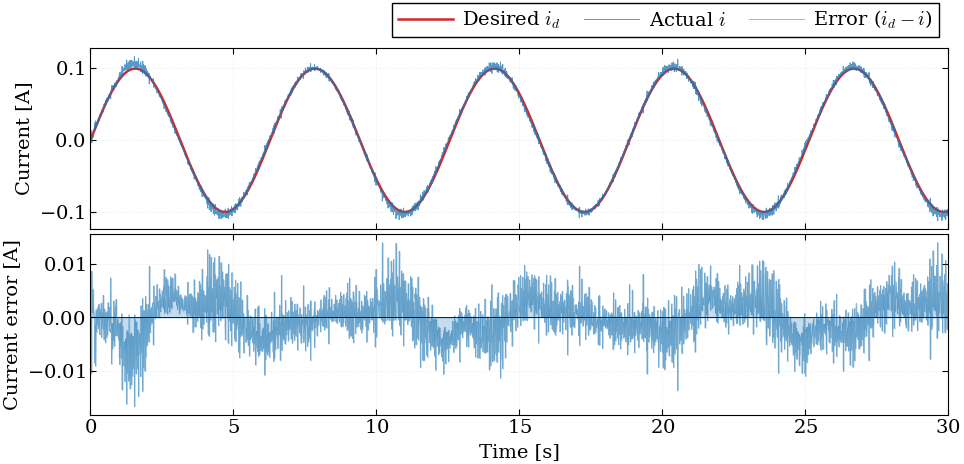

In [ ]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.io import loadmat

# ============================================================
# IEEE STYLE
# ============================================================
mpl.rcdefaults()
mpl.rcParams.update({
    # — To use full LaTeX rendering (requires texlive + cm-super), uncomment:
    # "text.usetex": True,
    # "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    # "font.serif": ["Computer Modern Roman"],
    # — Mathtext fallback (works everywhere):
    "mathtext.fontset": "cm",
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "axes.formatter.use_mathtext": True,
    # — Sizes
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    # — Axes / ticks
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.top": True,
    "ytick.right": True,
    # — Grid
    "axes.grid": True,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.linestyle": ":",
    # — Lines / legend
    "lines.linewidth": 1.4,
    "legend.frameon": True,
    "legend.framealpha": 1.0,
    "legend.edgecolor": "black",
    "legend.fancybox": False,
    "legend.handlelength": 2.8,
    # — Save
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
})

# ============================================================
# LOAD DATA
# ============================================================
mat = loadmat("torque_control_M1.mat")
simout = mat["simout"]          # shape (3001, 4)

i_desired = simout[:, 0]       # column 0: desired current
i_actual  = simout[:, 1]       # column 1: actual current

dt = 0.01                      # sampling period [s]
T  = len(i_desired)
time = np.arange(T) * dt

# ============================================================
# VISUAL ENCODING
#   Red  = desired / reference
#   Blue = actual / measured + error envelope
# ============================================================
C_DES = "#D62728"
C_ACT = "#1F77B4"

GT_LW = 1.8
MD_LW = 0.7
FIG_W = 10

# ============================================================
# FIGURE — CURRENT TRACKING + CURRENT ERROR
# ============================================================
fig, (ax_cur, ax_err) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Top: desired vs actual (clean lines, no markers) ----
ax_cur.plot(time, i_desired, color=C_DES, lw=GT_LW)
ax_cur.plot(time, i_actual,  color=C_ACT, lw=MD_LW, alpha=0.75)
ax_cur.set_ylabel(r"Current [A]")

# ---- Bottom: error as filled envelope ----
error = i_desired - i_actual
ax_err.fill_between(time, error, 0, color=C_ACT, alpha=0.25)
ax_err.plot(time, error, color=C_ACT, lw=0.6, alpha=0.5)
ax_err.axhline(0, color="black", ls="-", lw=0.6)
ax_err.set_ylabel(r"Current error [A]")
ax_err.set_xlabel(r"Time [s]")

# ---- Legend ----
h_legend = [
    Line2D([], [], color=C_DES, ls="-", lw=GT_LW,
           label=r"Desired $i_d$"),
    Line2D([], [], color=C_ACT, ls="-", lw=MD_LW, alpha=0.75,
           label=r"Actual $i$"),
    Line2D([], [], color=C_ACT, ls="-", lw=MD_LW, alpha=0.5,
           label=r"Error ($i_d - i$)"),
]

ax_cur.set_xlim(time[0], time[-1])
ax_cur.legend(
    handles=h_legend,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_legend),
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig.savefig("current_tracking_M1.png", format="png", dpi=600)
plt.show()

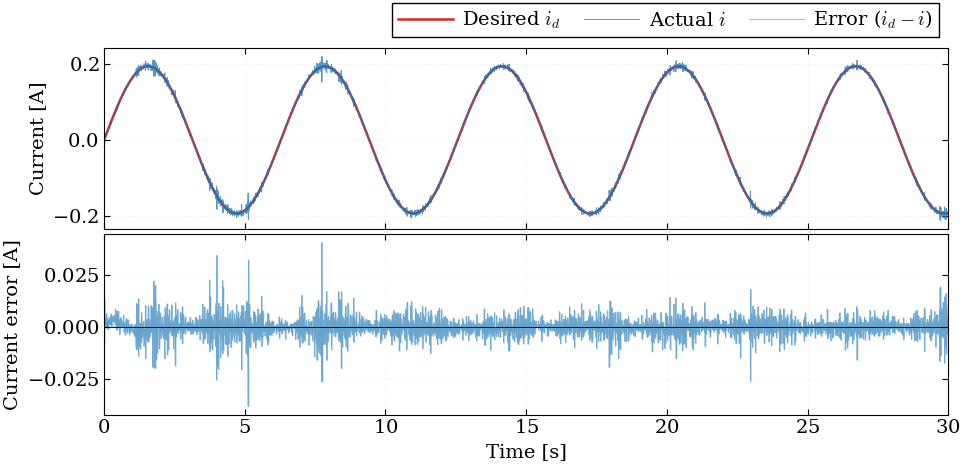

In [ ]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.io import loadmat

# ============================================================
# IEEE STYLE
# ============================================================
mpl.rcdefaults()
mpl.rcParams.update({
    # — To use full LaTeX rendering (requires texlive + cm-super), uncomment:
    # "text.usetex": True,
    # "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    # "font.serif": ["Computer Modern Roman"],
    # — Mathtext fallback (works everywhere):
    "mathtext.fontset": "cm",
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "axes.formatter.use_mathtext": True,
    # — Sizes
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    # — Axes / ticks
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.top": True,
    "ytick.right": True,
    # — Grid
    "axes.grid": True,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.linestyle": ":",
    # — Lines / legend
    "lines.linewidth": 1.4,
    "legend.frameon": True,
    "legend.framealpha": 1.0,
    "legend.edgecolor": "black",
    "legend.fancybox": False,
    "legend.handlelength": 2.8,
    # — Save
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
})

# ============================================================
# LOAD DATA
# ============================================================
mat = loadmat("torque_control_M2.mat")
simout = mat["simout"]          # shape (3001, 4)

i_desired = simout[:, 0]       # column 0: desired current
i_actual  = simout[:, 1]       # column 1: actual current

dt = 0.01                      # sampling period [s]
T  = len(i_desired)
time = np.arange(T) * dt

# ============================================================
# VISUAL ENCODING
#   Red  = desired / reference
#   Blue = actual / measured + error envelope
# ============================================================
C_DES = "#D62728"
C_ACT = "#1F77B4"

GT_LW = 1.8
MD_LW = 0.7
FIG_W = 10

# ============================================================
# FIGURE — CURRENT TRACKING + CURRENT ERROR
# ============================================================
fig, (ax_cur, ax_err) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Top: desired vs actual (clean lines, no markers) ----
ax_cur.plot(time, i_desired, color=C_DES, lw=GT_LW)
ax_cur.plot(time, i_actual,  color=C_ACT, lw=MD_LW, alpha=0.75)
ax_cur.set_ylabel(r"Current [A]")

# ---- Bottom: error as filled envelope ----
error = i_desired - i_actual
ax_err.fill_between(time, error, 0, color=C_ACT, alpha=0.25)
ax_err.plot(time, error, color=C_ACT, lw=0.6, alpha=0.5)
ax_err.axhline(0, color="black", ls="-", lw=0.6)
ax_err.set_ylabel(r"Current error [A]")
ax_err.set_xlabel(r"Time [s]")

# ---- Legend ----
h_legend = [
    Line2D([], [], color=C_DES, ls="-", lw=GT_LW,
           label=r"Desired $i_d$"),
    Line2D([], [], color=C_ACT, ls="-", lw=MD_LW, alpha=0.75,
           label=r"Actual $i$"),
    Line2D([], [], color=C_ACT, ls="-", lw=MD_LW, alpha=0.5,
           label=r"Error ($i_d - i$)"),
]

ax_cur.set_xlim(time[0], time[-1])
ax_cur.legend(
    handles=h_legend,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_legend),
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig.savefig("current_tracking_M2.png", format="png", dpi=600)
plt.show()